# ***TEXT PREPROCESSING DATA***

In [6]:
import pandas as pd

data = pd.read_csv("hasil_scraper_ulasan_app_mobile jkn.csv")
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35336 entries, 0 to 35335
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   probable_user_id  35336 non-null  object 
 1   reviewId          35336 non-null  object 
 2   userName          35336 non-null  object 
 3   userImage         35336 non-null  object 
 4   score             35336 non-null  int64  
 5   at                35336 non-null  object 
 6   content           35335 non-null  object 
 7   thumbsUpCount     0 non-null      float64
 8   replyContent      33722 non-null  object 
 9   replyAt           0 non-null      float64
dtypes: float64(2), int64(1), object(7)
memory usage: 2.7+ MB


In [7]:
data.head()

,probable_user_id,reviewId,userName,userImage,score,at,content,thumbsUpCount,replyContent,replyAt
0,img:c72c5fd7c20d0497d4a734ac427fe3d4a5b4e911,ea915ce1-93a4-4424-8df6-d288cecc1a49,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,1,2026-03-03T23:57:07,"disuruh verifikasi wajah, tapi selalu gagal, p...",NaN,NaN,NaN
1,img:c72c5fd7c20d0497d4a734ac427fe3d4a5b4e911,f5375edd-e857-4404-a233-5ea209914486,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,5,2026-03-03T23:21:07,bagus,NaN,NaN,NaN
2,img:c72c5fd7c20d0497d4a734ac427fe3d4a5b4e911,3f88fa9e-0084-45b9-9a06-6971c115784c,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,5,2026-03-03T23:19:43,terimakasih untuk semuanya,NaN,NaN,NaN
3,img:c72c5fd7c20d0497d4a734ac427fe3d4a5b4e911,957e1dfc-9d5e-46f4-98d0-a6fd4239969c,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,5,2026-03-03T23:15:55,layanannya mantap,NaN,NaN,NaN
4,img:c72c5fd7c20d0497d4a734ac427fe3d4a5b4e911,e577db27-b33f-4297-8909-528cbfda8d7a,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,5,2026-03-03T23:00:29,terima kasih mobile jkn sangat membantu sekali,NaN,NaN,NaN


In [8]:
df  = pd.DataFrame(data[['score','content']])
df.head(5)

,score,content
0,1,"disuruh verifikasi wajah, tapi selalu gagal, p..."
1,5,bagus
2,5,terimakasih untuk semuanya
3,5,layanannya mantap
4,5,terima kasih mobile jkn sangat membantu sekali


**PROSES CLEANING**

---



In [9]:
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35336 entries, 0 to 35335
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   score    35336 non-null  int64 
 1   content  35335 non-null  object
dtypes: int64(1), object(1)
memory usage: 552.3+ KB


,score,content
0,1,"disuruh verifikasi wajah, tapi selalu gagal, p..."
1,5,bagus
2,5,terimakasih untuk semuanya
3,5,layanannya mantap
4,5,terima kasih mobile jkn sangat membantu sekali


In [10]:
data = df[df.duplicated(subset="content", keep=False)]
data.info()
data.head()

<class 'pandas.core.frame.DataFrame'>
Index: 11787 entries, 1 to 35334
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   score    11787 non-null  int64 
 1   content  11787 non-null  object
dtypes: int64(1), object(1)
memory usage: 276.3+ KB


,score,content
1,5,bagus
12,5,sangat membantu
13,5,sangat baik
14,5,👍👍👍
19,5,sangat membantu


In [11]:
df.drop_duplicates(subset ="content", inplace = True)

df.info()
data.head()

<class 'pandas.core.frame.DataFrame'>
Index: 24487 entries, 0 to 35335
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   score    24487 non-null  int64 
 1   content  24486 non-null  object
dtypes: int64(1), object(1)
memory usage: 573.9+ KB


,score,content
1,5,bagus
12,5,sangat membantu
13,5,sangat baik
14,5,👍👍👍
19,5,sangat membantu


In [12]:
import re
import string
import nltk

def remove_URL(tweet):
    if tweet is not None and isinstance(tweet, str):
        url = re.compile(r'https?://\S+|www\.\S+')
        return url.sub(r'', tweet)
    else:
        return tweet

def remove_html(tweet):
    if tweet is not None and isinstance(tweet, str):
        html = re.compile(r'<.*?>')
        return html.sub(r'', tweet)
    else:
        return tweet

def remove_emoji(tweet):
    if tweet is not None and isinstance(tweet, str):
        emoji_pattern = re.compile("["
            u"\U0001F600-\U0001F64F"  # emoticons
            u"\U0001F300-\U0001F5FF"  # symbols & pictographs
            u"\U0001F680-\U0001F6FF"  # transport & map symbols
            u"\U0001F700-\U0001F77F"  # alchemical symbols
            u"\U0001F780-\U0001F7FF"  # Geometric Shapes Extended
            u"\U0001F800-\U0001F8FF"  # Supplemental Arrows-C
            u"\U0001FA00-\U0001FA6F"  # Chess Symbols
            u"\U0001FA70-\U0001FAFF"  # Symbols and Pictographs Extended-A
            u"\U0001F004-\U0001F0CF"  # Additional emoticons
            u"\U0001F1E0-\U0001F1FF"  # flags
                               "]+", flags=re.UNICODE)
        return emoji_pattern.sub(r'', tweet)
    else:
        return tweet

def remove_symbols(tweet):
    if tweet is not None and isinstance(tweet, str):
        tweet = re.sub(r'[^a-zA-Z0-9\s]', '', tweet)
    return tweet

def remove_numbers(tweet):
    if tweet is not None and isinstance(tweet, str):
        tweet = re.sub(r'\d', '', tweet)
    return tweet

def remove_usernames(text):
    if text is not None and isinstance(text, str):
        return re.sub(r'@\w+', '', text)
    else:
        return text

df['cleaning'] = df['content'].apply(lambda x: remove_URL(x))
df['cleaning'] = df['cleaning'].apply(lambda x: remove_usernames(x))
df['cleaning'] = df['cleaning'].apply(lambda x: remove_html(x))
df['cleaning'] = df['cleaning'].apply(lambda x: remove_emoji(x))
df['cleaning'] = df['cleaning'].apply(lambda x: remove_symbols(x))
df['cleaning'] = df['cleaning'].apply(lambda x: remove_numbers(x))

df.head(5)

,score,content,cleaning
0,1,"disuruh verifikasi wajah, tapi selalu gagal, p...",disuruh verifikasi wajah tapi selalu gagal pad...
1,5,bagus,bagus
2,5,terimakasih untuk semuanya,terimakasih untuk semuanya
3,5,layanannya mantap,layanannya mantap
4,5,terima kasih mobile jkn sangat membantu sekali,terima kasih mobile jkn sangat membantu sekali


**PROSES CASE FOLDING**

---



In [13]:
def case_folding(text):
    if isinstance(text, str):
        lowercase_text = text.lower()
        return lowercase_text
    else:
        return text

df['case_folding'] = df['cleaning'].apply(case_folding)
df.head(5)

,score,content,cleaning,case_folding
0,1,"disuruh verifikasi wajah, tapi selalu gagal, p...",disuruh verifikasi wajah tapi selalu gagal pad...,disuruh verifikasi wajah tapi selalu gagal pad...
1,5,bagus,bagus,bagus
2,5,terimakasih untuk semuanya,terimakasih untuk semuanya,terimakasih untuk semuanya
3,5,layanannya mantap,layanannya mantap,layanannya mantap
4,5,terima kasih mobile jkn sangat membantu sekali,terima kasih mobile jkn sangat membantu sekali,terima kasih mobile jkn sangat membantu sekali


**Normalisasi Kata**

---



In [14]:
import pandas as pd
import requests
from io import BytesIO

def replace_taboo_words(text, kamus_tidak_baku):
    if isinstance(text, str):
        words = text.split()
        replaced_words = []
        kalimat_baku = []
        kata_diganti = []
        kata_tidak_baku_hash = []

        for word in words:
            if word in kamus_tidak_baku:
                baku_word = kamus_tidak_baku[word]
                if isinstance(baku_word, str) and all(char.isalpha() for char in baku_word):
                    replaced_words.append(baku_word)
                    kalimat_baku.append(baku_word)
                    kata_diganti.append(word)
                    kata_tidak_baku_hash.append(hash(word))
            else:
                replaced_words.append(word)
        replaced_text = ' '.join(replaced_words)
    else:
        replaced_text = ''
        kalimat_baku = []
        kata_diganti = []
        kata_tidak_baku_hash = []

    return replaced_text, kalimat_baku, kata_diganti, kata_tidak_baku_hash

data = pd.DataFrame(df[['score','content','cleaning','case_folding']])
data.head()

,score,content,cleaning,case_folding
0,1,"disuruh verifikasi wajah, tapi selalu gagal, p...",disuruh verifikasi wajah tapi selalu gagal pad...,disuruh verifikasi wajah tapi selalu gagal pad...
1,5,bagus,bagus,bagus
2,5,terimakasih untuk semuanya,terimakasih untuk semuanya,terimakasih untuk semuanya
3,5,layanannya mantap,layanannya mantap,layanannya mantap
4,5,terima kasih mobile jkn sangat membantu sekali,terima kasih mobile jkn sangat membantu sekali,terima kasih mobile jkn sangat membantu sekali


In [15]:
url = "https://github.com/analysisdatasentiment/kamus_kata_baku/raw/main/kamuskatabaku.xlsx"
response = requests.get(url)
file_excel = BytesIO(response.content)
kamus_data = pd.read_excel(file_excel)

kamus_tidak_baku_dict = dict(zip(kamus_data['tidak_baku'], kamus_data['kata_baku']))

In [16]:
data[['normalisasi', 'Kata_Baku', 'Kata_Tidak_Baku', 'Kata_Tidak_Baku_Hash']] = data['case_folding'].apply(
    lambda x: pd.Series(replace_taboo_words(x, kamus_tidak_baku_dict))
)

df = pd.DataFrame(data[['content','cleaning','case_folding','normalisasi']])
df.head(20)

,content,cleaning,case_folding,normalisasi
0,"disuruh verifikasi wajah, tapi selalu gagal, p...",disuruh verifikasi wajah tapi selalu gagal pad...,disuruh verifikasi wajah tapi selalu gagal pad...,disuruh verifikasi wajah tapi selalu gagal pad...
1,bagus,bagus,bagus,bagus
2,terimakasih untuk semuanya,terimakasih untuk semuanya,terimakasih untuk semuanya,terimakasih untuk semuanya
3,layanannya mantap,layanannya mantap,layanannya mantap,layanannya mantap
4,terima kasih mobile jkn sangat membantu sekali,terima kasih mobile jkn sangat membantu sekali,terima kasih mobile jkn sangat membantu sekali,terima kasih mobile jkn sangat membantu sekali
5,kenapa 2 hari ini error setiap saya mau ambil ...,kenapa hari ini error setiap saya mau ambil a...,kenapa hari ini error setiap saya mau ambil a...,kenapa hari ini error setiap saya mau ambil an...
6,mudah aj w,mudah aj w,mudah aj w,mudah saja gue
7,apknya tolong diperbaiki lagi masak saya sudah...,apknya tolong diperbaiki lagi masak saya sudah...,apknya tolong diperbaiki lagi masak saya sudah...,apknya tolong diperbaiki lagi masak saya sudah...
8,membantu meningkatkan layanan ke masyarakat,membantu meningkatkan layanan ke masyarakat,membantu meningkatkan layanan ke masyarakat,membantu meningkatkan layanan ke masyarakat
9,"semoga bermanfaat, dan amanah",semoga bermanfaat dan amanah,semoga bermanfaat dan amanah,semoga bermanfaat dan amanah


**TOKENIZATION**

---



In [17]:
def tokenize(text):
    tokens = text.split()
    return tokens

df['tokenize'] = df['normalisasi'].apply(tokenize)

df.head(5)

,content,cleaning,case_folding,normalisasi,tokenize
0,"disuruh verifikasi wajah, tapi selalu gagal, p...",disuruh verifikasi wajah tapi selalu gagal pad...,disuruh verifikasi wajah tapi selalu gagal pad...,disuruh verifikasi wajah tapi selalu gagal pad...,"[disuruh, verifikasi, wajah, tapi, selalu, gag..."
1,bagus,bagus,bagus,bagus,[bagus]
2,terimakasih untuk semuanya,terimakasih untuk semuanya,terimakasih untuk semuanya,terimakasih untuk semuanya,"[terimakasih, untuk, semuanya]"
3,layanannya mantap,layanannya mantap,layanannya mantap,layanannya mantap,"[layanannya, mantap]"
4,terima kasih mobile jkn sangat membantu sekali,terima kasih mobile jkn sangat membantu sekali,terima kasih mobile jkn sangat membantu sekali,terima kasih mobile jkn sangat membantu sekali,"[terima, kasih, mobile, jkn, sangat, membantu,..."


**STOPWORD** **REMOVAL**

---



In [18]:
from nltk.corpus import stopwords
nltk.download('stopwords')
stop_words = stopwords.words('indonesian')

def remove_stopwords(tokens):
    return [w for w in tokens if w not in stop_words]

df["stopword_removal"] = df["tokenize"].apply(lambda x: " ".join(remove_stopwords(x)))

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [19]:
def remove_stopwords(text):
    return [word for word in text if word not in stop_words]

df['stopword removal'] = df['tokenize'].apply(
    lambda x: " ".join(remove_stopwords(x))
)

df.head(5)

,content,cleaning,case_folding,normalisasi,tokenize,stopword_removal,stopword removal
0,"disuruh verifikasi wajah, tapi selalu gagal, p...",disuruh verifikasi wajah tapi selalu gagal pad...,disuruh verifikasi wajah tapi selalu gagal pad...,disuruh verifikasi wajah tapi selalu gagal pad...,"[disuruh, verifikasi, wajah, tapi, selalu, gag...",disuruh verifikasi wajah gagal memenuhi persya...,disuruh verifikasi wajah gagal memenuhi persya...
1,bagus,bagus,bagus,bagus,[bagus],bagus,bagus
2,terimakasih untuk semuanya,terimakasih untuk semuanya,terimakasih untuk semuanya,terimakasih untuk semuanya,"[terimakasih, untuk, semuanya]",terimakasih,terimakasih
3,layanannya mantap,layanannya mantap,layanannya mantap,layanannya mantap,"[layanannya, mantap]",layanannya mantap,layanannya mantap
4,terima kasih mobile jkn sangat membantu sekali,terima kasih mobile jkn sangat membantu sekali,terima kasih mobile jkn sangat membantu sekali,terima kasih mobile jkn sangat membantu sekali,"[terima, kasih, mobile, jkn, sangat, membantu,...",terima kasih mobile jkn membantu,terima kasih mobile jkn membantu


In [20]:
from collections import Counter

all_text = ' '.join(df['stopword removal'].astype(str))
all_text = re.sub(r'[^a-zA-Z\s]', '', all_text.lower())

word_list = all_text.split()
word_freq = Counter(word_list)

sorted_freq = sorted(word_freq.items(), key=lambda x: x[1], reverse=True)
df_freq = pd.DataFrame(sorted_freq, columns=['Kata', 'Frekuensi'])

df_freq.to_csv('frekuensi_kata_awal.csv', index=False)
print("✅ File 'frekuensi_kata_awal.csv' berhasil disimpan.")
df_freq.info()
df_freq.head(50)

✅ File 'frekuensi_kata_awal.csv' berhasil disimpan.
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15958 entries, 0 to 15957
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Kata       15958 non-null  object
 1   Frekuensi  15958 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 249.5+ KB


,Kata,Frekuensi
0,aplikasi,7035
1,ya,4757
2,login,3108
3,daftar,2664
4,membantu,2480
5,masuk,2386
6,jkn,2332
7,susah,2080
8,mudah,1972
9,banget,1964


In [21]:
hapus_kata = ['ya','tok','deh','wok','we','the','wi','sih','roy','not','nih','cs','y','abang','bang','gue',
              'ya','gue','sih','koh','ust','the','nih']

df['stopword removal'] = df['stopword removal'].apply(
    lambda x: ' '.join([kata for kata in x.split() if kata not in hapus_kata]))

df['stopword removal'].str.contains('|'.join(hapus_kata)).sum()

np.int64(11009)

In [22]:
kamus_tidak_baku = {
    'hp':'handphone',
    'apk':'aplikasi',
    'app':'aplikasi'
}

def perbaiki_kata(teks):
    kata_list = teks.split()
    hasil = [kamus_tidak_baku.get(kata, kata) for kata in kata_list]
    return ' '.join(hasil)

df['stopword removal'] = df['stopword removal'].astype(str).apply(perbaiki_kata)


In [23]:
from collections import Counter
import re

all_text = ' '.join(df['stopword removal'].astype(str))
all_text = re.sub(r'[^a-zA-Z\s]', '', all_text.lower())

word_list = all_text.split()
word_freq = Counter(word_list)

sorted_freq = sorted(word_freq.items(), key=lambda x: x[1], reverse=True)
df_freq = pd.DataFrame(sorted_freq, columns=['Kata', 'Frekuensi'])

df_freq.head(50)

,Kata,Frekuensi
0,aplikasi,8606
1,login,3108
2,daftar,2664
3,membantu,2480
4,masuk,2386
5,jkn,2332
6,susah,2080
7,mudah,1972
8,banget,1964
9,bagus,1889


**WORDCLOUD SETELAH PREPROCESSING**

---



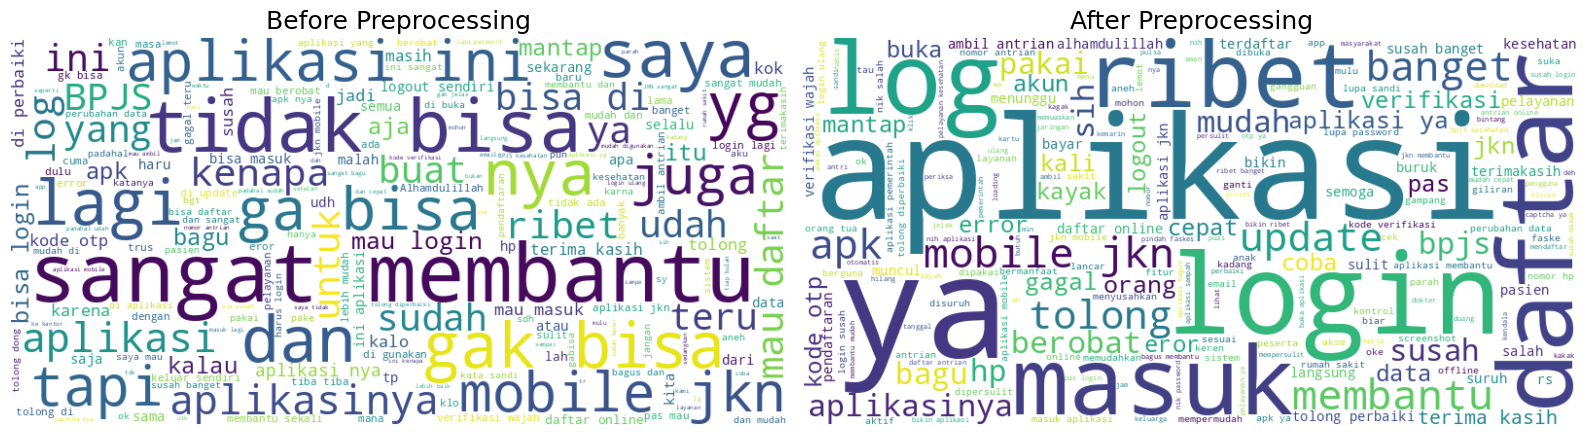

In [24]:
import pandas as pd
import numpy as np
from PIL import Image
from wordcloud import WordCloud, STOPWORDS, ImageColorGenerator
import matplotlib.pyplot as plt

stopwords = set(STOPWORDS)
stopwords.update(['https', 'co', 'RT', '...', 'amp', 'lu','jokowi'])

text_before = ' '.join(
    df['content']
    .astype(str)
    .tolist()
)

wc_before = WordCloud(
    stopwords=stopwords,
    background_color="white",
    max_words=200,
    width=800,
    height=400
).generate(text_before)

text_after = ' '.join(df['stopword_removal'].astype(str).tolist())

wc_after = WordCloud(
    stopwords=stopwords,
    background_color="white",
    max_words=200,
    width=800,
    height=400
).generate(text_after)

plt.figure(figsize=(16, 8))

plt.subplot(1, 2, 1)
plt.imshow(wc_before, interpolation='bilinear')
plt.axis("off")
plt.title("Before Preprocessing", fontsize=18)

plt.subplot(1, 2, 2)
plt.imshow(wc_after, interpolation='bilinear')
plt.axis("off")
plt.title("After Preprocessing", fontsize=18)

plt.tight_layout()
plt.show()

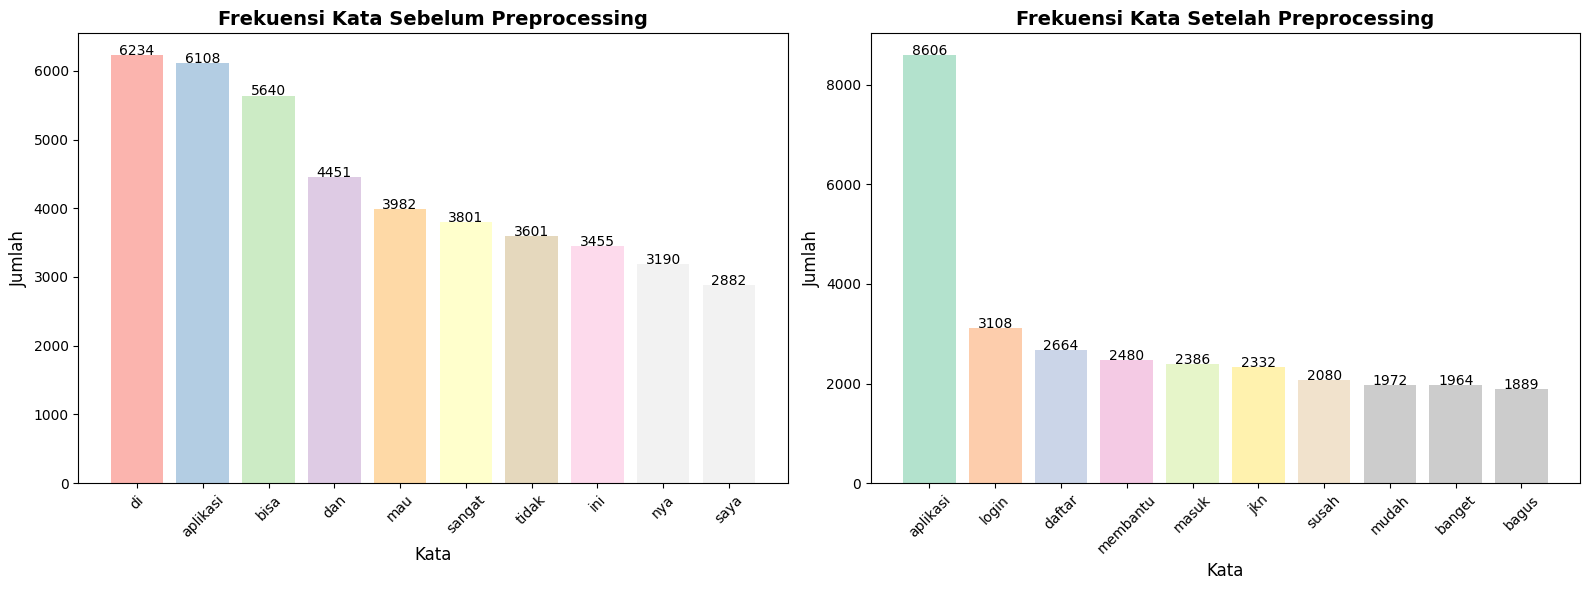

In [25]:
import matplotlib.pyplot as plt
from collections import Counter
from wordcloud import STOPWORDS
import re

stopwords = set(STOPWORDS)
stopwords.update(['https', 'co', 'RT', '...', 'amp', 'lu'])

def clean_text_column(series):
    cleaned = []
    for text in series.astype(str):
        text = re.sub(r"[\[\]\'\",]", "", text)
        cleaned.append(text.strip())
    return " ".join(cleaned)

all_text_before = clean_text_column(df["content"])
words_before = all_text_before.split()
filtered_words_before = [word for word in words_before if word.lower() not in stopwords]
word_counts_before = Counter(filtered_words_before)
top_words_before = word_counts_before.most_common(10)
word_before, count_before = zip(*top_words_before)

all_text_after = clean_text_column(df["stopword removal"])
words_after = all_text_after.split()
filtered_words_after = [word for word in words_after if word.lower() not in stopwords]
word_counts_after = Counter(filtered_words_after)
top_words_after = word_counts_after.most_common(10)
word_after, count_after = zip(*top_words_after)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

colors_before = plt.cm.Pastel1(range(len(word_before)))
bars1 = axes[0].bar(word_before, count_before, color=colors_before)
axes[0].set_title("Frekuensi Kata Sebelum Preprocessing", fontsize=14, fontweight='bold')
axes[0].set_xlabel("Kata", fontsize=12)
axes[0].set_ylabel("Jumlah", fontsize=12)
axes[0].tick_params(axis='x', rotation=45)
for bar, count in zip(bars1, count_before):
    axes[0].text(bar.get_x() + bar.get_width()/2, count + 1, str(count), ha='center')

colors_after = plt.cm.Pastel2(range(len(word_after)))
bars2 = axes[1].bar(word_after, count_after, color=colors_after)
axes[1].set_title("Frekuensi Kata Setelah Preprocessing", fontsize=14, fontweight='bold')
axes[1].set_xlabel("Kata", fontsize=12)
axes[1].set_ylabel("Jumlah", fontsize=12)
axes[1].tick_params(axis='x', rotation=45)
for bar, count in zip(bars2, count_after):
    axes[1].text(bar.get_x() + bar.get_width()/2, count + 1, str(count), ha='center')

plt.tight_layout()
plt.show()

In [26]:
df.to_csv('Hasil_Preprocessing_Data.csv',encoding='utf8', index=False);
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
Index: 24487 entries, 0 to 35335
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   content           24486 non-null  object
 1   cleaning          24486 non-null  object
 2   case_folding      24486 non-null  object
 3   normalisasi       24487 non-null  object
 4   tokenize          24487 non-null  object
 5   stopword_removal  24487 non-null  object
 6   stopword removal  24487 non-null  object
dtypes: object(7)
memory usage: 1.5+ MB


,content,cleaning,case_folding,normalisasi,tokenize,stopword_removal,stopword removal
0,"disuruh verifikasi wajah, tapi selalu gagal, p...",disuruh verifikasi wajah tapi selalu gagal pad...,disuruh verifikasi wajah tapi selalu gagal pad...,disuruh verifikasi wajah tapi selalu gagal pad...,"[disuruh, verifikasi, wajah, tapi, selalu, gag...",disuruh verifikasi wajah gagal memenuhi persya...,disuruh verifikasi wajah gagal memenuhi persya...
1,bagus,bagus,bagus,bagus,[bagus],bagus,bagus
2,terimakasih untuk semuanya,terimakasih untuk semuanya,terimakasih untuk semuanya,terimakasih untuk semuanya,"[terimakasih, untuk, semuanya]",terimakasih,terimakasih
3,layanannya mantap,layanannya mantap,layanannya mantap,layanannya mantap,"[layanannya, mantap]",layanannya mantap,layanannya mantap
4,terima kasih mobile jkn sangat membantu sekali,terima kasih mobile jkn sangat membantu sekali,terima kasih mobile jkn sangat membantu sekali,terima kasih mobile jkn sangat membantu sekali,"[terima, kasih, mobile, jkn, sangat, membantu,...",terima kasih mobile jkn membantu,terima kasih mobile jkn membantu


# ***PELEBELAN DATA METODE LAXICON BASED 2 CLASS***

In [27]:
import pandas as pd

data = pd.read_csv("Hasil_Preprocessing_Data.csv")
data.info()
data.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24487 entries, 0 to 24486
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   content           24486 non-null  object
 1   cleaning          24422 non-null  object
 2   case_folding      24422 non-null  object
 3   normalisasi       24405 non-null  object
 4   tokenize          24487 non-null  object
 5   stopword_removal  24290 non-null  object
 6   stopword removal  24283 non-null  object
dtypes: object(7)
memory usage: 1.3+ MB


,content,cleaning,case_folding,normalisasi,tokenize,stopword_removal,stopword removal
0,"disuruh verifikasi wajah, tapi selalu gagal, p...",disuruh verifikasi wajah tapi selalu gagal pad...,disuruh verifikasi wajah tapi selalu gagal pad...,disuruh verifikasi wajah tapi selalu gagal pad...,"['disuruh', 'verifikasi', 'wajah', 'tapi', 'se...",disuruh verifikasi wajah gagal memenuhi persya...,disuruh verifikasi wajah gagal memenuhi persya...
1,bagus,bagus,bagus,bagus,['bagus'],bagus,bagus
2,terimakasih untuk semuanya,terimakasih untuk semuanya,terimakasih untuk semuanya,terimakasih untuk semuanya,"['terimakasih', 'untuk', 'semuanya']",terimakasih,terimakasih
3,layanannya mantap,layanannya mantap,layanannya mantap,layanannya mantap,"['layanannya', 'mantap']",layanannya mantap,layanannya mantap
4,terima kasih mobile jkn sangat membantu sekali,terima kasih mobile jkn sangat membantu sekali,terima kasih mobile jkn sangat membantu sekali,terima kasih mobile jkn sangat membantu sekali,"['terima', 'kasih', 'mobile', 'jkn', 'sangat',...",terima kasih mobile jkn membantu,terima kasih mobile jkn membantu


In [28]:
data = pd.DataFrame(data[['stopword removal']])
data.head(5)

,stopword removal
0,disuruh verifikasi wajah gagal memenuhi persya...
1,bagus
2,terimakasih
3,layanannya mantap
4,terima kasih mobile jkn membantu


In [33]:
import pandas as pd
import requests

positive_url = "https://raw.githubusercontent.com/fajri91/InSet/master/positive.tsv"
negative_url = "https://raw.githubusercontent.com/fajri91/InSet/master/negative.tsv"

positive_lexicon = set(pd.read_csv(positive_url, sep="\t", header=None)[0])
negative_lexicon = set(pd.read_csv(negative_url, sep="\t", header=None)[0])

def determine_sentiment_3class(text, threshold=1):
    """
    threshold=1 bikin kelas netral lebih masuk akal (tidak terlalu sedikit).
    score >  threshold -> Positif
    score < -threshold -> Negatif
    else -> Netral
    """
    if not isinstance(text, str):
        return 0, "Netral"

    pos = sum(1 for w in text.split() if w in positive_lexicon)
    neg = sum(1 for w in text.split() if w in negative_lexicon)
    score = pos - neg

    if score > threshold:
        label = "Positif"
    elif score < -threshold:
        label = "Negatif"
    else:
        label = "Netral"
    return score, label

data[["Score", "Sentiment"]] = data["stopword_removal"].apply(lambda x: pd.Series(determine_sentiment_3class(x, threshold=1)))

print("\nDistribusi kelas:")
print(data["Sentiment"].value_counts())
print("\nPersentase kelas:")
print((data["Sentiment"].value_counts(normalize=True) * 100).round(2))



Distribusi kelas:
Sentiment
Netral     17064
Negatif     5838
Positif     1585
Name: count, dtype: int64

Persentase kelas:
Sentiment
Netral     69.69
Negatif    23.84
Positif     6.47
Name: proportion, dtype: float64


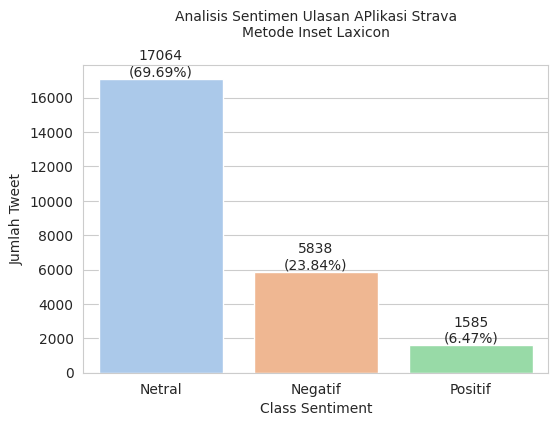

In [34]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

sentiment_count = data['Sentiment'].value_counts()
sns.set_style('whitegrid')

fig, ax = plt.subplots(figsize=(6, 4))
ax = sns.barplot(x=sentiment_count.index, y=sentiment_count.values, palette='pastel')
plt.title('Analisis Sentimen Ulasan APlikasi Strava\nMetode Inset Laxicon', fontsize=10, pad=20)
plt.xlabel('Class Sentiment', fontsize=10)
plt.ylabel('Jumlah Tweet', fontsize=10)

total = len(data['Sentiment'])

for i, count in enumerate(sentiment_count.values):
    percentage = f'{100 * count / total:.2f}%'
    ax.text(i, count + 0.10, f'{count}\n({percentage})', ha='center', va='bottom')

plt.show()

In [35]:
data.to_csv('Hasil_Labelling_Data_Inset_Lax.csv',encoding='utf8', index=False)

**WORDCLOUD & FREKUENSI KATA NGRAM**

In [36]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import CountVectorizer
from wordcloud import WordCloud

df = pd.read_csv("Hasil_Labelling_Data_Inset_Lax.csv")

df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24487 entries, 0 to 24486
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   stopword_removal  24283 non-null  object
 1   Score             24487 non-null  int64 
 2   Sentiment         24487 non-null  object
dtypes: int64(1), object(2)
memory usage: 574.0+ KB


,stopword_removal,Score,Sentiment
0,disuruh verifikasi wajah gagal memenuhi persya...,-7,Negatif
1,bagus,0,Netral
2,terimakasih,1,Netral
3,layanannya mantap,1,Netral
4,terima kasih mobile jkn membantu,1,Netral


In [38]:
# Pastikan tidak ada nilai kosong
df = df.dropna(subset=['stopword_removal', 'Sentiment'])
df.head()

,stopword_removal,Score,Sentiment
0,disuruh verifikasi wajah gagal memenuhi persya...,-7,Negatif
1,bagus,0,Netral
2,terimakasih,1,Netral
3,layanannya mantap,1,Netral
4,terima kasih mobile jkn membantu,1,Netral


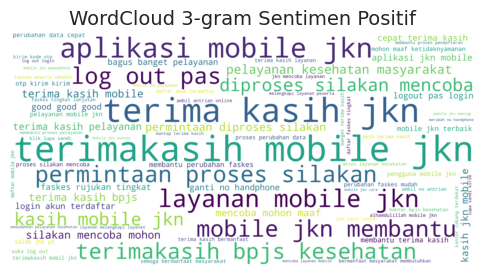

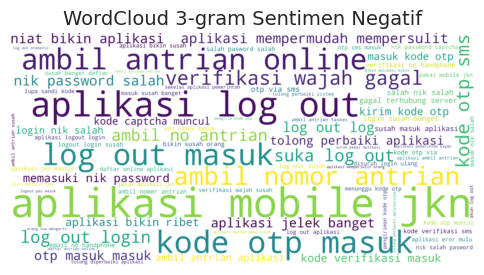

In [40]:
def wordcloud_ngram(data, sentiment_label, ngram_range=(2,3), max_words=1000):
    text_data = data[data['Sentiment'] == sentiment_label]['stopword_removal']
    text_data = text_data.dropna()
    text_data = text_data[text_data.str.len() > 0]

    vectorizer = CountVectorizer(ngram_range=ngram_range)
    X = vectorizer.fit_transform(text_data)

    word_freq = dict(zip(
        vectorizer.get_feature_names_out(),
        X.sum(axis=0).A1
    ))

    # filter frekuensi kecil
    word_freq = {k: v for k, v in word_freq.items() if v > 2}

    wc = WordCloud(
        width=1000,
        height=500,
        background_color='white',
        max_words=max_words,
        prefer_horizontal=0.9,
        relative_scaling=0.5,
        collocations=False,
        min_font_size=8,
        max_font_size=120,
        scale=5
    ).generate_from_frequencies(word_freq)

    plt.figure(figsize=(6,4))
    plt.imshow(wc, interpolation='bilinear')
    plt.axis('off')
    plt.title(f'WordCloud {ngram_range[0]}-gram Sentimen {sentiment_label}', fontsize=14)
    plt.show()

wordcloud_ngram(df, 'Positif', ngram_range=(3,3))
print()
wordcloud_ngram(df, 'Negatif', ngram_range=(3,3))

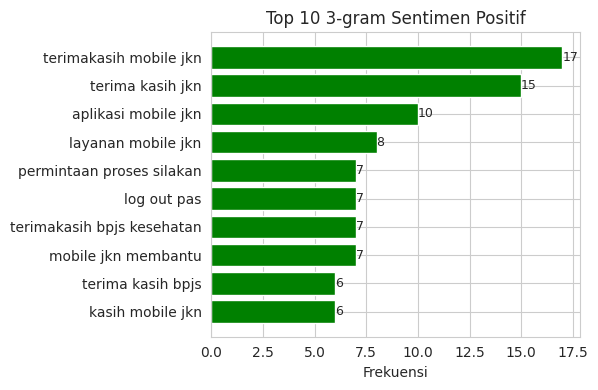

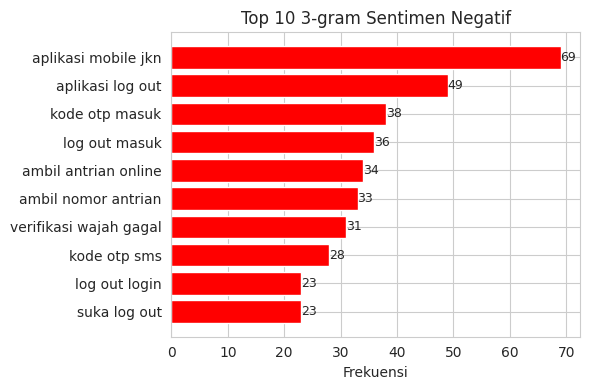

In [41]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer

def plot_top_ngram(data, sentiment_label,
                   ngram_range=(2,2),
                   top_n=10,
                   color='blue'):

    text_data = data[data['Sentiment'] == sentiment_label]['stopword_removal']

    vectorizer = CountVectorizer(ngram_range=ngram_range)
    X = vectorizer.fit_transform(text_data)

    freq_df = pd.DataFrame({
        'ngram': vectorizer.get_feature_names_out(),
        'frequency': X.sum(axis=0).A1
    }).sort_values(by='frequency', ascending=False).head(top_n)

    plt.figure(figsize=(6,4))
    bars = plt.barh(freq_df['ngram'], freq_df['frequency'], color=color)
    plt.gca().invert_yaxis()

    plt.xlabel('Frekuensi')
    plt.title(f'Top {top_n} {ngram_range[0]}-gram Sentimen {sentiment_label}')

    for bar in bars:
        width = bar.get_width()
        plt.text(
            width,
            bar.get_y() + bar.get_height()/2,
            f'{int(width)}',
            va='center',
            ha='left',
            fontsize=9
        )

    plt.tight_layout()
    plt.show()


plot_top_ngram(df, 'Positif', ngram_range=(3,3), color='green')
print()
plot_top_ngram(df, 'Negatif', ngram_range=(3,3), color='red')

# **5 SKEMA PELATIHAN**

In [47]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline

from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import ComplementNB
from sklearn.linear_model import RidgeClassifier, PassiveAggressiveClassifier
from sklearn.calibration import CalibratedClassifierCV

if "stopword_removal" not in data.columns and "stopword removal" in data.columns:
    data = data.rename(columns={"stopword removal": "stopword_removal"})

data = data.dropna(subset=["stopword_removal", "Sentiment"]).copy()
X_all = data["stopword_removal"].astype(str)
y_all = data["Sentiment"].astype(str)

print("Distribusi kelas:")
print(y_all.value_counts())

label_order = ["Negatif", "Netral", "Positif"]

label_order = [l for l in label_order if l in set(y_all)] or sorted(y_all.unique().tolist())

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all,
    test_size=0.2, random_state=42, stratify=y_all
)

experiments = [
    ("SGD_char_3_5_balanced",
     Pipeline([
         ("tfidf", TfidfVectorizer(analyzer="char", ngram_range=(3,5),
                                   min_df=2, max_df=0.95, sublinear_tf=True,
                                   max_features=400000)),
         ("clf", SGDClassifier(loss="hinge", alpha=1e-5, max_iter=4000,
                               class_weight="balanced", random_state=42))
     ])),

    ("LinearSVC_char_wb_3_5_balanced",
     Pipeline([
         ("tfidf", TfidfVectorizer(analyzer="char_wb", ngram_range=(3,5),
                                   min_df=2, max_df=0.95, sublinear_tf=True,
                                   max_features=400000)),
         ("clf", LinearSVC(class_weight="balanced"))
     ])),

    ("Ridge_word_1_2",
     Pipeline([
         ("tfidf", TfidfVectorizer(ngram_range=(1,2), min_df=2, max_df=0.9,
                                   sublinear_tf=True, max_features=300000)),
         ("clf", RidgeClassifier())
     ])),

    ("PassiveAggressive_word_1_2_balanced",
     Pipeline([
         ("tfidf", TfidfVectorizer(ngram_range=(1,2), min_df=2, max_df=0.9,
                                   sublinear_tf=True, max_features=300000)),
         ("clf", PassiveAggressiveClassifier(max_iter=2000, class_weight="balanced", random_state=42))
     ])),


    ("ComplementNB_word_1_2",
     Pipeline([
         ("tfidf", TfidfVectorizer(ngram_range=(1,2), min_df=2, max_df=0.95,
                                   sublinear_tf=True, max_features=300000)),
         ("clf", ComplementNB(alpha=0.5))
     ])),
]

results = []
best_name, best_pipe, best_test = None, None, -1

for name, pipe in experiments:
    pipe.fit(X_train, y_train)

    pred_train = pipe.predict(X_train)
    pred_test  = pipe.predict(X_test)

    train_acc = accuracy_score(y_train, pred_train)
    test_acc  = accuracy_score(y_test, pred_test)

    results.append({
        "Model": name,
        "Train Acc (%)": round(train_acc*100, 2),
        "Test Acc (%)": round(test_acc*100, 2)
    })

    print(f"\n===== {name} =====")
    print(f"Train Acc: {train_acc*100:.2f}% | Test Acc: {test_acc*100:.2f}%")

    if test_acc > best_test:
        best_test = test_acc
        best_name = name
        best_pipe = pipe

summary = pd.DataFrame(results).sort_values("Test Acc (%)", ascending=False)
print("\n===== RINGKASAN (urut Test Acc) =====")
print(summary.to_string(index=False))

print(f"\n✅ BEST MODEL: {best_name} | Test Acc: {best_test*100:.2f}%")

Distribusi kelas:
Sentiment
Netral     16860
Negatif     5838
Positif     1585
Name: count, dtype: int64

===== SGD_char_3_5_balanced =====
Train Acc: 98.82% | Test Acc: 88.00%

===== LinearSVC_char_wb_3_5_balanced =====
Train Acc: 96.09% | Test Acc: 88.84%

===== Ridge_word_1_2 =====
Train Acc: 94.67% | Test Acc: 84.58%

===== PassiveAggressive_word_1_2_balanced =====
Train Acc: 99.89% | Test Acc: 85.51%

===== ComplementNB_word_1_2 =====
Train Acc: 79.65% | Test Acc: 69.10%

===== RINGKASAN (urut Test Acc) =====
                              Model  Train Acc (%)  Test Acc (%)
     LinearSVC_char_wb_3_5_balanced          96.09         88.84
              SGD_char_3_5_balanced          98.82         88.00
PassiveAggressive_word_1_2_balanced          99.89         85.51
                     Ridge_word_1_2          94.67         84.58
              ComplementNB_word_1_2          79.65         69.10

✅ BEST MODEL: LinearSVC_char_wb_3_5_balanced | Test Acc: 88.84%
